# Stairway + hyperbolic codes — logical error rate vs $p_z$ (fixed $p_{\text{res}}$)

Curves of logical error rate (per observable per round) vs Bell-pair $Z$ error rate `p_bell_z` for
each `[[n,k,d]]` code, at a **fixed** residual noise `p_res`. This is a single vertical slice of the
`(p_res, p_z)` grid — the same slice `tools/_grid_scans/plot_grid.py` draws — rendered in the
sinter-plotter style of `high_rate_stairway.ipynb`.

Two code families are overlaid with **separate color palettes**:
- **Stairway** (`out/collection/grid_stairway*.csv`) — warm colors.
- **Hyperbolic Floquet** (`out/collection/grid_hyperbolic_for_stairway.csv`) — cold colors.

Within each family, color = code (ordered by `n`) and linestyle = scheme (`noise_model`).

In [1]:
import ast
import datetime
import glob
import json
import re
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import sinter

# Reuse the shared paper rcParams so this figure matches the high-rate figures.
from high_rate_analysis import set_paper_style

%load_ext autoreload
%autoreload 2

In [ ]:
# ---- Config -----------------------------------------------------------------
STAIR_CSV_GLOB = '../out/collection/grid_stairway*.csv'
HYP_CSV_GLOB = '../out/collection/grid_hyperbolic_for_stairway*.csv'
P_RES = 1e-4        # fixed residual-noise slice (snapped to nearest sampled value)

# Color encoding: the REP scheme picks the palette family.
#   1-rep  -> warm colors,  5-rep -> cold colors  (stairway, colored by code).
# Hyperbolic is reduced to a single code, drawn in greyscale so it reads as a
# reference curve rather than competing with the stairway palettes.
SCHEME_CMAP = {
    'biased_bell_v3_equivalent': 'autumn',            # 1-rep: warm
    'biased_bell_v3_equivalent_majority5': 'winter',  # 5-rep: cold
}
HYP_ONLY_CODE = '[[256,10,4]]'   # keep just this hyperbolic code
HYP_GREY = {
    'biased_bell_v3_equivalent': '0.55',              # 1-rep: grey
    'biased_bell_v3_equivalent_majority5': '0.0',     # 5-rep: black
}

# Legend labels + linestyle per scheme (noise_model column).
SCHEME_LABEL = {
    'biased_bell_v3_equivalent': '1-rep',
    'biased_bell_v3_equivalent_majority': '3-rep',
    'biased_bell_v3_equivalent_majority5': '5-rep',
}
SCHEME_LS = {
    'biased_bell_v3_equivalent': '-',
    'biased_bell_v3_equivalent_majority': '--',
    'biased_bell_v3_equivalent_majority5': ':',
}

In [18]:
def _parse_meta(s):
    """Parse a json_metadata cell: sinter CSV (JSON) or dated pandas CSV (repr)."""
    if not isinstance(s, str):
        return dict(s)
    try:
        return json.loads(s)
    except (json.JSONDecodeError, ValueError):
        return ast.literal_eval(s)


_AGG = {
    'shots': 'sum', 'errors': 'sum', 'discards': 'sum', 'seconds': 'sum',
    'decoder': 'first', 'json_metadata': 'first',
}

# n / k / d parsed from a hyperbolic input-circuit filename, used as a fallback
# when the sidecar metadata doesn't carry them (stairway carries them directly).
_NKD_FILE = re.compile(r'n=(\d+)_k=(\d+)_d=(\d+)')


def _nkd(meta):
    """Resolve (n, k, d): prefer sidecar metadata, fall back to the filename."""
    n, k = meta.get('n'), meta.get('k')
    d = meta.get('expected_distance', meta.get('d'))
    if n is not None and k is not None and d is not None:
        return (int(n), int(k), int(d))
    mm = _NKD_FILE.search(meta.get('input_circuit', '') or '')
    if mm:
        return tuple(int(x) for x in mm.groups())
    return (None, None, None)


def load_slice(csv_glob, p_res):
    """Load grid CSV(s), merge repeated runs, keep one p_res slice.

    Returns (df, p_res_used, code_order). The two CSV formats (sinter-JSON from
    --resume and dated pandas-repr from append mode) are merged by strong_id, so
    shots/errors for the same task accumulate across files. n/k/d come from the
    metadata (stairway) or the input-circuit filename (hyperbolic).
    """
    files = sorted(glob.glob(csv_glob))
    if not files:
        raise FileNotFoundError(f'No files matched: {csv_glob}')
    # skipinitialspace: sinter's CSV header pads column names with spaces.
    df = pd.concat([pd.read_csv(f, skipinitialspace=True) for f in files],
                   ignore_index=True)
    df = df.groupby('strong_id').agg(_AGG).reset_index()

    meta = df['json_metadata'].apply(_parse_meta)
    df['p'] = meta.apply(lambda m: m.get('p'))
    df['p_bell_z'] = meta.apply(lambda m: m.get('p_bell_z'))
    df['noise_model'] = meta.apply(lambda m: m.get('noise_model'))
    df[['n', 'k', 'd']] = pd.DataFrame(meta.apply(_nkd).tolist(), index=df.index)
    df['code'] = df.apply(
        lambda r: f"[[{int(r['n'])},{int(r['k'])},{int(r['d'])}]]", axis=1)

    # Snap the requested p_res to the nearest actually-sampled value.
    avail = np.array(sorted(df['p'].dropna().unique()))
    p_used = float(avail[np.argmin(np.abs(avail - p_res))])
    df = df[np.isclose(df['p'].astype(float), p_used)].reset_index(drop=True)

    # Drop under-sampled points (few shots and few errors -> noisy estimate).
    df = df[(df['shots'] > 200000) | (df['errors'] > 300)]

    code_order = df.drop_duplicates('code').sort_values('n')['code'].tolist()
    return df, p_used, code_order


def df_to_tasks(df):
    """Rebuild sinter.TaskStats from merged rows (n/k/d injected into metadata)."""
    tasks = []
    for _, row in df.iterrows():
        m = _parse_meta(row['json_metadata'])
        m['n'], m['k'], m['expected_distance'] = int(row['n']), int(row['k']), int(row['d'])
        tasks.append(sinter.TaskStats(
            strong_id=row['strong_id'], decoder=row['decoder'], json_metadata=m,
            shots=int(row['shots']), errors=int(row['errors']),
            discards=int(row['discards']), seconds=float(row['seconds']),
        ))
    return tasks


df_stair, p_used, order_stair = load_slice(STAIR_CSV_GLOB, P_RES)
df_hyp, p_used_h, order_hyp = load_slice(HYP_CSV_GLOB, P_RES)
assert np.isclose(p_used, p_used_h), (p_used, p_used_h)

# Combined scheme order (known schemes first, in SCHEME_LABEL order).
_present = pd.concat([df_stair['noise_model'], df_hyp['noise_model']]).dropna().unique()
schemes = [s for s in SCHEME_LABEL if s in set(_present)]
schemes += [s for s in _present if s not in schemes]

print(f'p_res used = {p_used:g} (requested {P_RES:g})')
print(f'stairway:   {len(df_stair)} rows, codes {order_stair}')
print(f'hyperbolic: {len(df_hyp)} rows, codes {order_hyp}')
print(f'schemes: {schemes}')
df_stair.head()

p_res used = 0.0001 (requested 0.0001)
stairway:   72 rows, codes ['[[192,6,9]]', '[[192,16,4]]', '[[288,14,10]]']
hyperbolic: 150 rows, codes ['[[64,10,2]]', '[[256,10,4]]', '[[576,10,6]]']
schemes: ['biased_bell_v3_equivalent', 'biased_bell_v3_equivalent_majority5']


,strong_id,shots,errors,discards,seconds,decoder,json_metadata,p,p_bell_z,noise_model,n,k,d,code
1,0779a576314faa387509dbb19cdf40edf3642426c38cc5...,1280000,2,0,2.492788e+05,tesseract_short,"{'p': 0.0001, 'rounds': -1, 'noise_model': 'bi...",0.0001,0.001520,biased_bell_v3_equivalent_majority5,192,6,9,"[[192,6,9]]"
2,0d1acec0c3b0c58518bee435948aca950a8909cf7a3481...,1280000,212,0,6.527587e+04,tesseract_short,"{'p': 0.0001, 'rounds': -1, 'noise_model': 'bi...",0.0001,0.002310,biased_bell_v3_equivalent_majority5,192,16,4,"[[192,16,4]]"
3,0e3c136d8b6324d51ad8a708bdbea73606156f1a1e24b7...,1940000,50,0,1.020849e+06,tesseract_short,"{'p': 0.0001, 'rounds': -1, 'noise_model': 'bi...",0.0001,0.001874,biased_bell_v3_equivalent,288,14,10,"[[288,14,10]]"
5,1022323b8c3f809050e4ed2d8d3eddc1768cca6a86c67e...,1280000,325,0,8.800809e+04,tesseract_short,"{'p': 0.0001, 'rounds': -1, 'noise_model': 'bi...",0.0001,0.018738,biased_bell_v3_equivalent_majority5,192,16,4,"[[192,16,4]]"
6,1049b65a3406874838f0c5c7a60540f7ae3af347277cb7...,5450000,0,0,2.384948e+05,tesseract_short,"{'p': 0.0001, 'rounds': -1, 'noise_model': 'bi...",0.0001,0.000231,biased_bell_v3_equivalent,192,6,9,"[[192,6,9]]"


Saved ../out/figures/20260720_stairway_hyperbolic_grid_pres0.0001.pdf


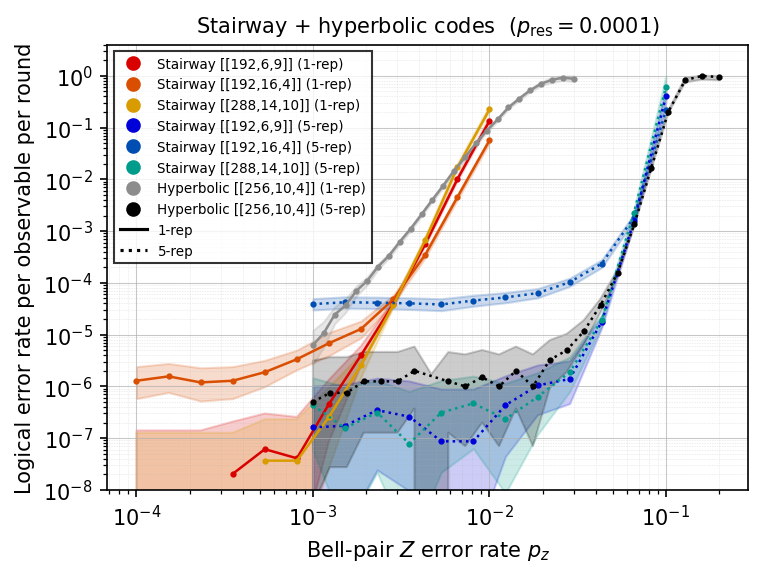

In [19]:
# LER (per observable per round) vs p_z at fixed p_res.
#   Stairway:   color = code, palette chosen by rep-scheme (1-rep warm / 5-rep cold).
#   Hyperbolic: single code (n=256), greyscale (1-rep grey / 5-rep black).
# linestyle still encodes the scheme. Drawn with sinter.plot_error_rate.
set_paper_style()


def make_colors(order, cmap_name, lo=0.0, hi=0.72, darken=1.0):
    """Map each code to a color sampled from cmap_name (avoiding the pale end).

    ``darken`` < 1 scales the RGB toward black (1.0 = unchanged).
    """
    cmap = plt.get_cmap(cmap_name)
    denom = max(1, len(order) - 1)
    colors = {}
    for i, code in enumerate(order):
        r, g, b, a = cmap(lo + (hi - lo) * i / denom)
        colors[code] = (r * darken, g * darken, b * darken, a)
    return colors


# Reduce hyperbolic to the single requested code.
df_hyp_one = df_hyp[df_hyp['code'] == HYP_ONLY_CODE]

fig, ax = plt.subplots(1, 1, figsize=(5.2, 4))


def draw(sdf, scheme, color_of):
    """Plot one (family, scheme) group; color_of(code) -> color."""
    if sdf.empty:
        return
    ls = SCHEME_LS.get(scheme, '-')

    def plot_args_func(index, group_key, group_stats, _ls=ls):
        code = group_key.split(']]')[0].replace(' ', '') + ']]'
        return {'color': color_of(code), 'linestyle': _ls,
                'marker': '.', 'markersize': 4, 'linewidth': 1.2}

    sinter.plot_error_rate(
        ax=ax,
        stats=df_to_tasks(sdf),
        x_func=lambda s: s.json_metadata['p_bell_z'],
        group_func=lambda s: (f"[[{s.json_metadata['n']}, {s.json_metadata['k']}, "
                              f"{s.json_metadata['expected_distance']}]]"),
        plot_args_func=plot_args_func,
        failure_units_per_shot_func=lambda s: s.json_metadata['expected_distance'],
        failure_values_func=lambda s: s.json_metadata['k'],
    )


# Stairway: per-code color from the scheme's warm/cold palette.
stair_colors = {}   # scheme -> {code: color}, kept for the legend
for scheme in schemes:
    cmap_name = SCHEME_CMAP.get(scheme)
    if cmap_name is None:
        continue
    cols = make_colors(order_stair, cmap_name, darken=0.85)
    stair_colors[scheme] = cols
    draw(df_stair[df_stair['noise_model'] == scheme], scheme,
         color_of=lambda code, _c=cols: _c.get(code, 'k'))

# Hyperbolic (single code): greyscale per scheme.
for scheme in schemes:
    grey = HYP_GREY.get(scheme)
    if grey is None:
        continue
    draw(df_hyp_one[df_hyp_one['noise_model'] == scheme], scheme,
         color_of=lambda code, _g=grey: _g)

ax.loglog()
ax.set_xlabel(r'Bell-pair $Z$ error rate $p_z$')
ax.set_ylabel(r'Logical error rate per observable per round')
ax.set_title(rf'Stairway + hyperbolic codes  ($p_{{\text{{res}}}} = {p_used:g}$)')
ax.set_ylim(1e-8, 4)
ax.grid(which='major', linestyle='-', linewidth=0.5, alpha=0.7)
ax.grid(which='minor', linestyle=':', linewidth=0.3, alpha=0.5)

# Legend: stairway code colors (per scheme), hyperbolic greys, then linestyles.
handles = []
for scheme in schemes:
    if scheme not in stair_colors:
        continue
    lbl = SCHEME_LABEL.get(scheme, scheme)
    for c in order_stair:
        handles.append(Line2D([0], [0], color=stair_colors[scheme][c],
                              marker='o', linestyle='',
                              label=f"Stairway {c} ({lbl})"))
for scheme in schemes:
    if scheme not in HYP_GREY or df_hyp_one[df_hyp_one['noise_model'] == scheme].empty:
        continue
    lbl = SCHEME_LABEL.get(scheme, scheme)
    handles.append(Line2D([0], [0], color=HYP_GREY[scheme], marker='o',
                          linestyle='', label=f"Hyperbolic {HYP_ONLY_CODE} ({lbl})"))
handles += [Line2D([0], [0], color='k', linestyle=SCHEME_LS.get(s, '-'),
                   label=SCHEME_LABEL.get(s, s)) for s in schemes]
ax.legend(handles=handles, fontsize=6.5, frameon=True, edgecolor='black',
          fancybox=False)

fig.tight_layout()
fig.set_dpi(150)

out_dir = Path('../out/figures')
out_dir.mkdir(parents=True, exist_ok=True)
date = datetime.date.today().strftime('%Y%m%d')
out_path = out_dir / f'{date}_stairway_hyperbolic_grid_pres{p_used:g}.pdf'
fig.savefig(out_path, bbox_inches='tight')
print(f'Saved {out_path}')
plt.show()